In [75]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from pywaffle import Waffle


In [76]:
sns.set_style('darkgrid')

In [95]:
df= pd.read_csv("Salaries.csv")

In [78]:
df.head()

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Unnamed: 0          300 non-null    int64
 1   work_year           300 non-null    int64
 2   experience_level    300 non-null    str  
 3   employment_type     300 non-null    str  
 4   job_title           300 non-null    str  
 5   salary              300 non-null    int64
 6   salary_currency     300 non-null    str  
 7   salary_in_usd       300 non-null    int64
 8   employee_residence  300 non-null    str  
 9   remote_ratio        300 non-null    int64
 10  company_location    300 non-null    str  
 11  company_size        300 non-null    str  
dtypes: int64(5), str(7)
memory usage: 28.3 KB


In [80]:
df.tail()

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
295,295,2022,SE,FT,Data Engineer,154000,USD,154000,US,100,US,M
296,296,2022,SE,FT,Data Engineer,126000,USD,126000,US,100,US,M
297,297,2022,SE,FT,Data Analyst,129000,USD,129000,US,0,US,M
298,298,2022,SE,FT,Data Analyst,150000,USD,150000,US,100,US,M
299,299,2022,MI,FT,AI Scientist,200000,USD,200000,IN,100,US,L


In [81]:
df.isnull().sum()

Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

In [82]:
df.columns

Index(['Unnamed: 0', 'work_year', 'experience_level', 'employment_type',
       'job_title', 'salary', 'salary_currency', 'salary_in_usd',
       'employee_residence', 'remote_ratio', 'company_location',
       'company_size'],
      dtype='str')

In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
df.drop(columns=['Unnamed: 0'], inplace=True, errors='ignore')

In [85]:
df.duplicated().sum()

np.int64(290)

In [86]:
df[df.duplicated(keep=False)]

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L
...,...,...,...,...,...,...,...,...,...,...,...
295,2022,SE,FT,Data Engineer,154000,USD,154000,US,100,US,M
296,2022,SE,FT,Data Engineer,126000,USD,126000,US,100,US,M
297,2022,SE,FT,Data Analyst,129000,USD,129000,US,0,US,M
298,2022,SE,FT,Data Analyst,150000,USD,150000,US,100,US,M


In [87]:
df.drop_duplicates(inplace=True)

In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           10 non-null     int64
 1   experience_level    10 non-null     str  
 2   employment_type     10 non-null     str  
 3   job_title           10 non-null     str  
 4   salary              10 non-null     int64
 5   salary_currency     10 non-null     str  
 6   salary_in_usd       10 non-null     int64
 7   employee_residence  10 non-null     str  
 8   remote_ratio        10 non-null     int64
 9   company_location    10 non-null     str  
 10  company_size        10 non-null     str  
dtypes: int64(4), str(7)
memory usage: 1012.0 bytes


In [89]:
df.reset_index(drop=True, inplace=True)

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           10 non-null     int64
 1   experience_level    10 non-null     str  
 2   employment_type     10 non-null     str  
 3   job_title           10 non-null     str  
 4   salary              10 non-null     int64
 5   salary_currency     10 non-null     str  
 6   salary_in_usd       10 non-null     int64
 7   employee_residence  10 non-null     str  
 8   remote_ratio        10 non-null     int64
 9   company_location    10 non-null     str  
 10  company_size        10 non-null     str  
dtypes: int64(4), str(7)
memory usage: 1012.0 bytes


In [91]:
categorical_col= ['experince_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'emoployee_residence', 'remote_ratio', 'company_location', 'company size']

<span style="font-size:45px;">1. Box Plot</span>


C:\Users\Bassel\AppData\Local\Temp\ipykernel_29756\1318410041.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['title_status'], y=df['price'], palette='viridis')


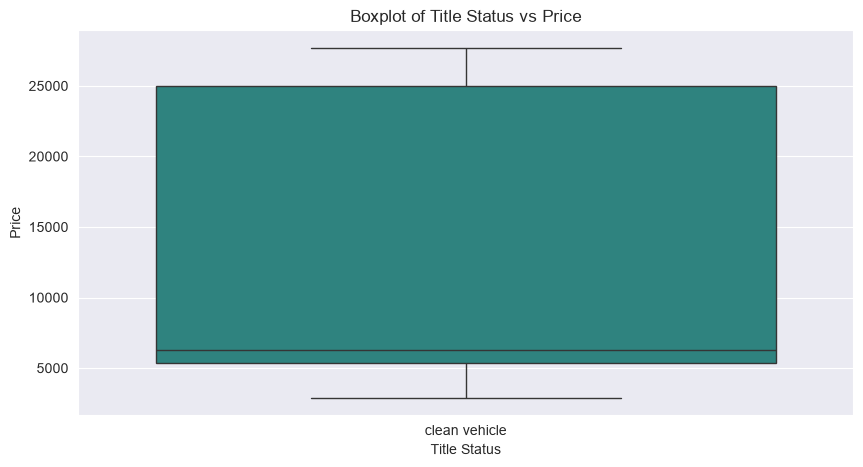

In [119]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['title_status'], y=df['price'], palette='viridis')
plt.xlabel('Title Status')
plt.ylabel('Price')
plt.title('Boxplot of Title Status vs Price')
plt.show()

<span style="font-size:45px">2. Histplot</span>

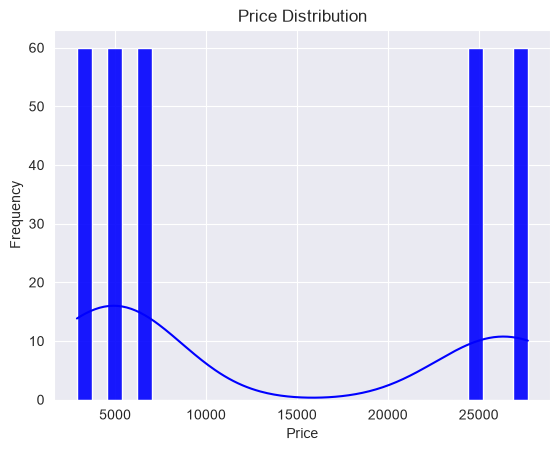

In [98]:
plt.Figure(figsize=(10, 5))
sns.histplot(df["price"], bins=30, kde=True, color='blue', alpha=0.9)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price Distribution")
plt.show()



<span style="font-size:45px">Pie chart</span>


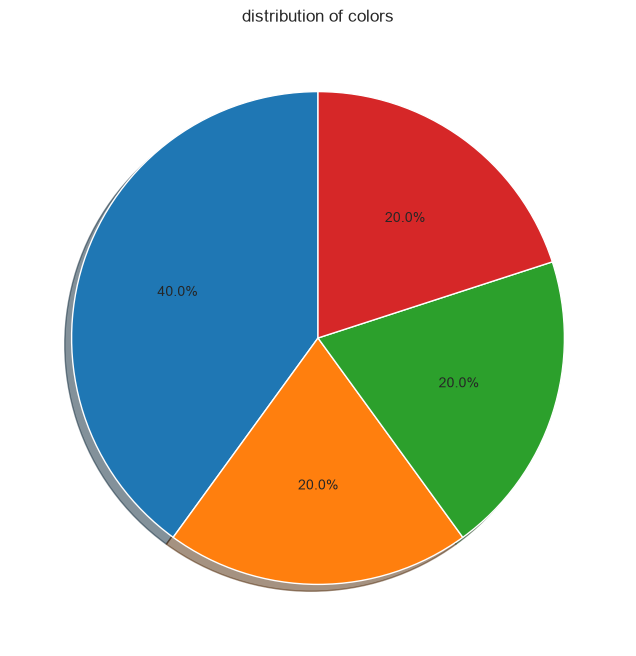

In [120]:
color_counts= df['color'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(color_counts, autopct='%1.1f%%', shadow=True, startangle=90)
plt.title('distribution of colors')
plt.show()

In [97]:
df= pd.read_csv("cars.csv")
df

,Unnamed: 0,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition
0,0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
1,1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
2,2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
3,3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left
4,4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left
...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,295,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
296,296,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
297,297,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
298,298,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left


In [99]:
df.duplicated().sum()

np.int64(0)

In [100]:
df.drop(columns=['Unnamed: 0'], inplace=True)


In [101]:
df.duplicated().sum()

np.int64(295)

In [102]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   price         300 non-null    int64  
 1   brand         300 non-null    str    
 2   model         300 non-null    str    
 3   year          300 non-null    int64  
 4   title_status  300 non-null    str    
 5   mileage       300 non-null    float64
 6   color         300 non-null    str    
 7   vin           300 non-null    str    
 8   lot           300 non-null    int64  
 9   state         300 non-null    str    
 10  country       300 non-null    str    
 11  condition     300 non-null    str    
dtypes: float64(1), int64(3), str(8)
memory usage: 28.3 KB


In [103]:
df.isnull().sum()

price           0
brand           0
model           0
year            0
title_status    0
mileage         0
color           0
vin             0
lot             0
state           0
country         0
condition       0
dtype: int64

In [104]:
df[df.select_dtypes('str').columns]=df.select_dtypes('object').astype('category')

C:\Users\Bassel\AppData\Local\Temp\ipykernel_29756\987274106.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df[df.select_dtypes('str').columns]=df.select_dtypes('object').astype('category')


In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   price         300 non-null    int64   
 1   brand         300 non-null    category
 2   model         300 non-null    category
 3   year          300 non-null    int64   
 4   title_status  300 non-null    category
 5   mileage       300 non-null    float64 
 6   color         300 non-null    category
 7   vin           300 non-null    category
 8   lot           300 non-null    int64   
 9   state         300 non-null    category
 10  country       300 non-null    category
 11  condition     300 non-null    category
dtypes: category(8), float64(1), int64(3)
memory usage: 12.1 KB


In [106]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,300.0,13449.8,1.064339e+04,2899.0,5350.0,6300.0,25000.0,27700.0
year,300.0,2013.8,3.925732e+00,2008.0,2011.0,2014.0,2018.0,2018.0
mileage,300.0,115011.8,1.012015e+05,6654.0,39590.0,64146.0,190552.0,274117.0
lot,300.0,165894581.6,3.292265e+06,159348797.0,166951262.0,167655728.0,167753855.0,167763266.0


In [107]:
df["kilometers"] = df["mileage"]*1.60934

In [108]:
df.head()

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition,kilometers
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left,441147.45278
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left,306662.95568
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left,63713.77060
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left,103232.72364
4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left,10708.54836


In [109]:
df.drop(columns=['kilometers'])

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left
4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left
...,...,...,...,...,...,...,...,...,...,...,...,...
295,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
296,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
297,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
298,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left


In [110]:
df1 = df[df['price']>0]
print(f'number of cars after removing 0 prices:{df.shape[0]}')


number of cars after removing 0 prices:300


<span style='font-size:45pt'>Line plot</span>

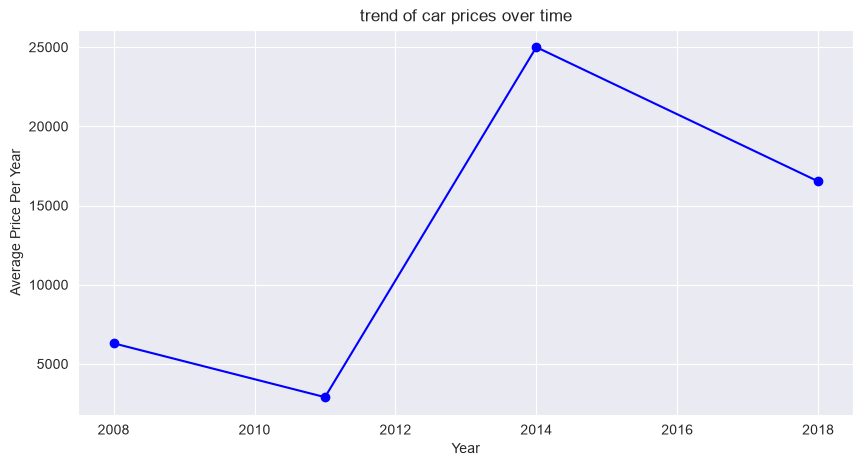

In [111]:
avg_price_per_year = df.groupby('year')['price'].mean()

plt.figure(figsize=(10,5))
plt.plot(avg_price_per_year.index, avg_price_per_year.values, marker='o', linestyle='-', color='blue', label='Average Price Per Year')
plt.xlabel('Year')
plt.ylabel('Average Price Per Year')
plt.title('trend of car prices over time')
plt.show()

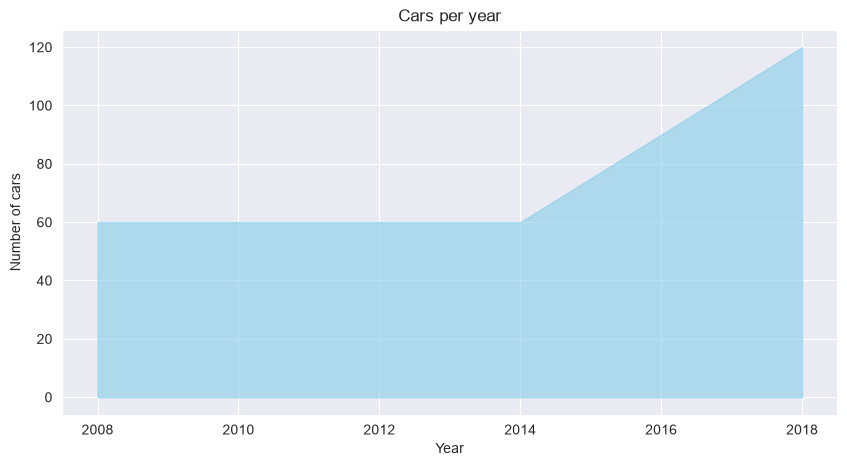

In [112]:
cars_per_year = df["year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.fill_between(cars_per_year.index, cars_per_year.values, color="skyblue", alpha=0.6)
plt.xlabel("Year")
plt.ylabel("Number of cars")
plt.title("Cars per year")
plt.show()

<span style='font-size:45px'>bar plot</span>

C:\Users\Bassel\AppData\Local\Temp\ipykernel_29756\1879820310.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_by_brand.index, y=avg_price_by_brand.values, palette='viridis')


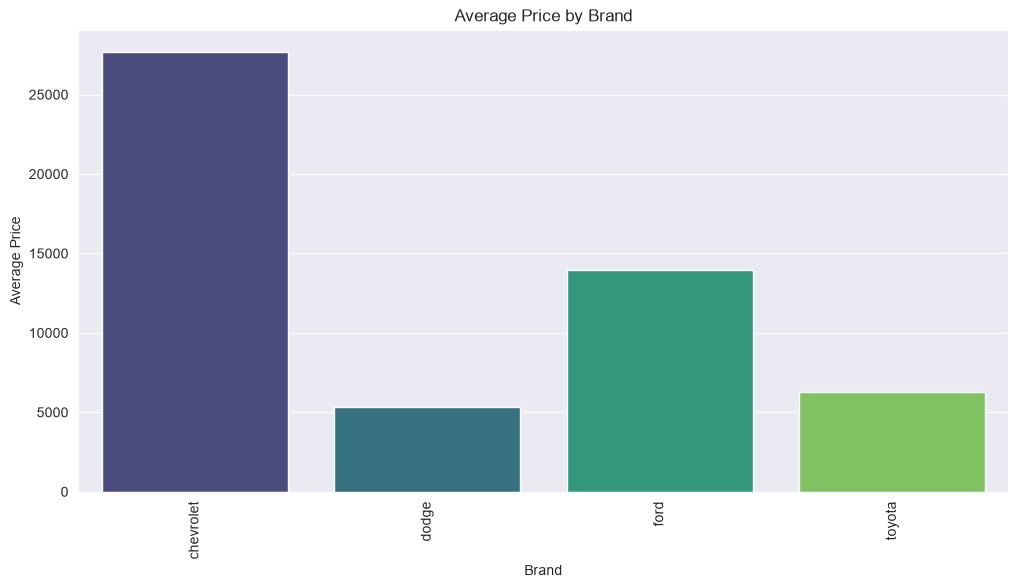

In [113]:
avg_price_by_brand = df.groupby('brand')['price'].mean().sort_values()

plt.figure(figsize=(12,6))
sns.barplot(x=avg_price_by_brand.index, y=avg_price_by_brand.values, palette='viridis')
plt.xticks(rotation=90)
plt.xlabel('Brand')
plt.ylabel('Average Price')
plt.title('Average Price by Brand')
plt.show()

<span style='font-size:45px'>Bubble plot</span>

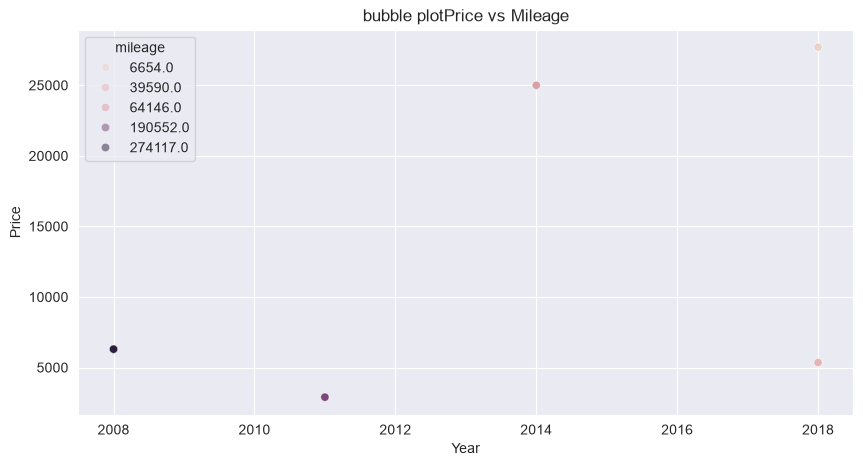

In [114]:
plt.figure(figsize=(10,5))
sns.scatterplot(x=df['year'], y=df['price'], hue=df['mileage'], sizes=(10,300), alpha=0.5)
plt.xlabel('Year')
plt.ylabel('Price')
plt.title('bubble plotPrice vs Mileage')
plt.show()